In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("C:\\Users\\stajyergrup5\\Desktop\\S.M.G\\predictive-maintenance-app\ai4i2020.csv")

OSError: [Errno 22] Invalid argument: 'C:\\Users\\stajyergrup5\\Desktop\\S.M.G\\predictive-maintenance-app\x07i4i2020.csv'

In [3]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [5]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

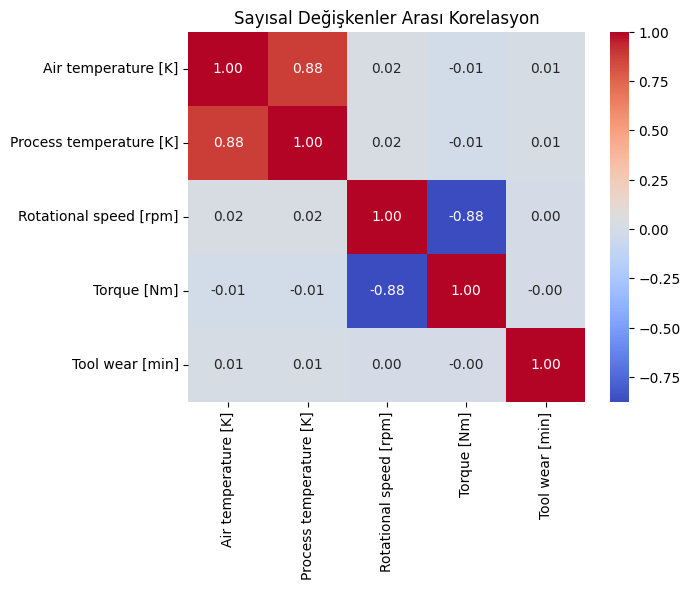

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Sayısal Değişkenler Arası Korelasyon')
plt.show()

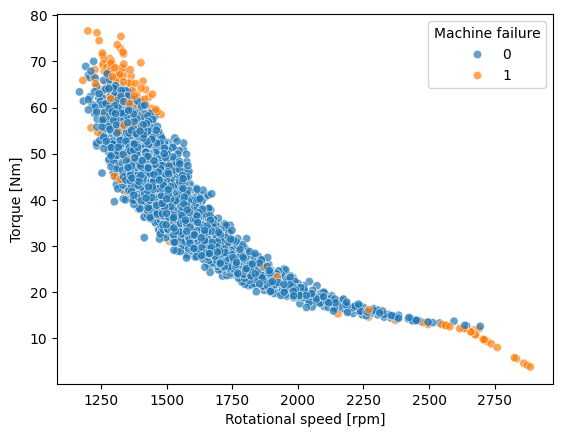

In [8]:
sns.scatterplot(data=df, x='Rotational speed [rpm]', y='Torque [Nm]', hue='Machine failure', alpha=0.7)
plt.show()

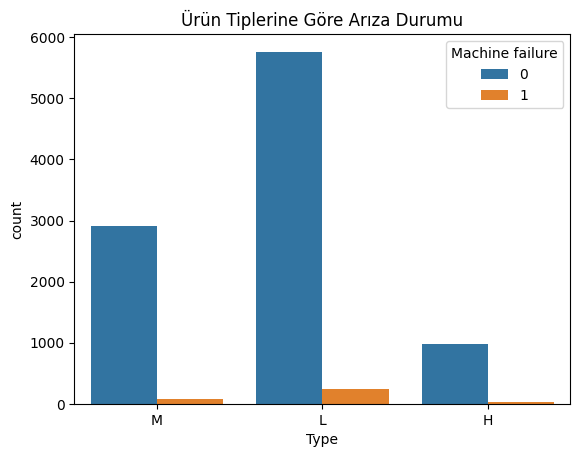

In [9]:
sns.countplot(data=df, x='Type', hue='Machine failure')
plt.title('Ürün Tiplerine Göre Arıza Durumu')
plt.show()

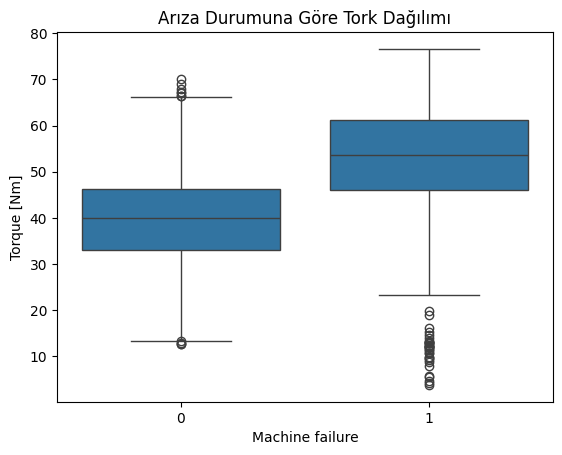

In [10]:
sns.boxplot(data=df, x='Machine failure', y='Torque [Nm]')
plt.title('Arıza Durumuna Göre Tork Dağılımı')
plt.show()

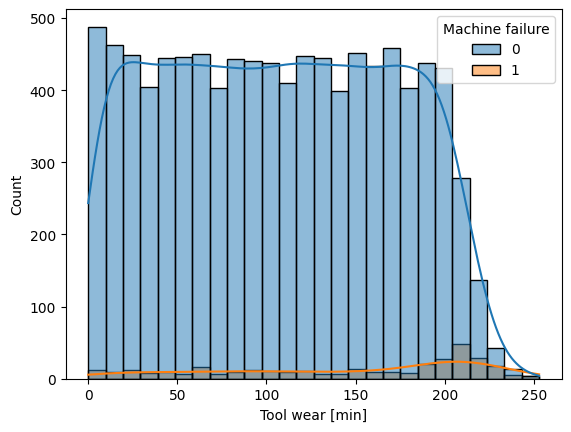

In [11]:
sns.histplot(data=df, x='Tool wear [min]', kde=True, hue='Machine failure')
plt.show()
from sklearn.model_selection import train_test_split

# 1. Hedef (y) ve Öznitelikleri (X) ayırma
y = df["Machine failure"]

# Hedef değişkeni ve gereksiz/kopya verecek kolonları X'ten düşürüyoruz
X = df.drop(["Machine failure", "UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"], axis=1)

# 2. 'Type' gibi metin ifadeleri sayısallaştırma
X = pd.get_dummies(X, columns=["Type"], drop_first=True)

# 3. Train ve Test olarak ayırma
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Hedef (y) ve Öznitelikleri (X) ayırma
y = df["Machine failure"]

# Hedef değişkeni ve gereksiz/kopya verecek kolonları X'ten düşürüyoruz
X = df.drop(["Machine failure", "UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"], axis=1)

# 2. 'Type' gibi metin ifadeleri sayısallaştırma
X = pd.get_dummies(X, columns=["Type"], drop_first=True)

# 3. Train ve Test olarak ayırma
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [13]:
# 1. Doğru modeli ve metrikleri içe aktarma
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# 2. Modeli oluşturma ve eğitme
tree_clf = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_clf.fit(X_train, y_train)

# 3. Test verisi ile tahmin yapma (y_pred tanımlama)
y_pred = tree_clf.predict(X_test)

# 4. Doğruluk skoru ve detaylı rapor alma
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy Score: 0.971
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      1932
           1       0.81      0.19      0.31        68

    accuracy                           0.97      2000
   macro avg       0.89      0.59      0.65      2000
weighted avg       0.97      0.97      0.96      2000



In [14]:
!pip install xgboost

In [15]:
# Sütun isimlerindeki '[', ']' ve '<' karakterlerini temizliyoruz
X.columns = X.columns.str.replace('[', '', regex=False).str.replace(']', '', regex=False).str.replace('<', '', regex=False)

# Ardından Train-Test ayrımını ve model eğitimini tekrar çalıştırın:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

xgb_clf = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42
)

xgb_clf.fit(X_train, y_train)

# Tahmin
y_pred = xgb_clf.predict(X_test)
print("Accuracy Score:", accuracy_score(y_test, y_pred))

Accuracy Score: 0.985


In [16]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score

# 1. Taranacak parametre ızgarasını (grid) tanımlıyoruz
param_grid = {
    'n_estimators': [50, 100, 200],         # Oluşturulacak ağaç sayısı
    'max_depth': [3, 5, 7],                  # Ağaçların maksimum derinliği
    'learning_rate': [0.01, 0.05, 0.1],      # Öğrenme oranı (eta)
    'subsample': [0.8, 1.0],                 # Veri örnekleme oranı
    'colsample_bytree': [0.8, 1.0]           # Öznitelik örnekleme oranı
}

# 2. Temel XGBoost modelini oluşturuyoruz
base_xgb = XGBClassifier(random_state=42, eval_metric='logloss')

# 3. GridSearchCV ile en iyi parametre kombinasyonunu arıyoruz
# cv=5: 5 Katlı çapraz doğrulama (Cross-Validation)
# scoring='f1': Sınıf dengesizliği olduğu için F1-Score'a göre en iyiyi seçer
grid_search = GridSearchCV(
    estimator=base_xgb,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,      # Tüm işlemci çekirdeklerini kullanarak hızlandırır
    verbose=1
)

# 4. Arama işlemini başlatıyoruz
grid_search.fit(X_train, y_train)

# 5. En iyi parametreleri ve skoru yazdırıyoruz
print("En İyi Parametreler:", grid_search.best_params_)
print("En İyi CV F1 Skoru:", grid_search.best_score_)

# 6. Bulunan en iyi model ile test verisi üzerinde tahmin yapıyoruz
best_xgb = grid_search.best_estimator_
y_pred_best = best_xgb.predict(X_test)

# 7. Sonuçları değerlendirme
print("\n--- Tuned Model Performansı ---")
print("Accuracy Score:", accuracy_score(y_test, y_pred_best))
print("\nSınıflandırma Raporu:\n", classification_report(y_test, y_pred_best))

Fitting 5 folds for each of 108 candidates, totalling 540 fits
En İyi Parametreler: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 1.0}
En İyi CV F1 Skoru: 0.749607971864981

--- Tuned Model Performansı ---
Accuracy Score: 0.988

Sınıflandırma Raporu:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.92      0.71      0.80        68

    accuracy                           0.99      2000
   macro avg       0.96      0.85      0.90      2000
weighted avg       0.99      0.99      0.99      2000

